In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [3]:
import numpy as np

# rows=True (Low, Medium, High), cols= Predicted(Low, Medium, High)
cms = {
    "SVM":         np.array([[107,152,33],[76,218,67],[51,119,72]]),
    "BanglaBERT":  np.array([[106,172,14],[90,221,50],[50,143,49]]),
    "XLM-RoBERTa": np.array([[109,183,0],[92,269,0],[57,185,0]]),
}
for name, cm in cms.items():
    assert list(cm.sum(axis=1)) == [292, 361, 242], name
    print(name, "accuracy = %.2f%%" % (cm.trace()/895*100))

SVM accuracy = 44.36%
BanglaBERT accuracy = 42.01%
XLM-RoBERTa accuracy = 42.23%


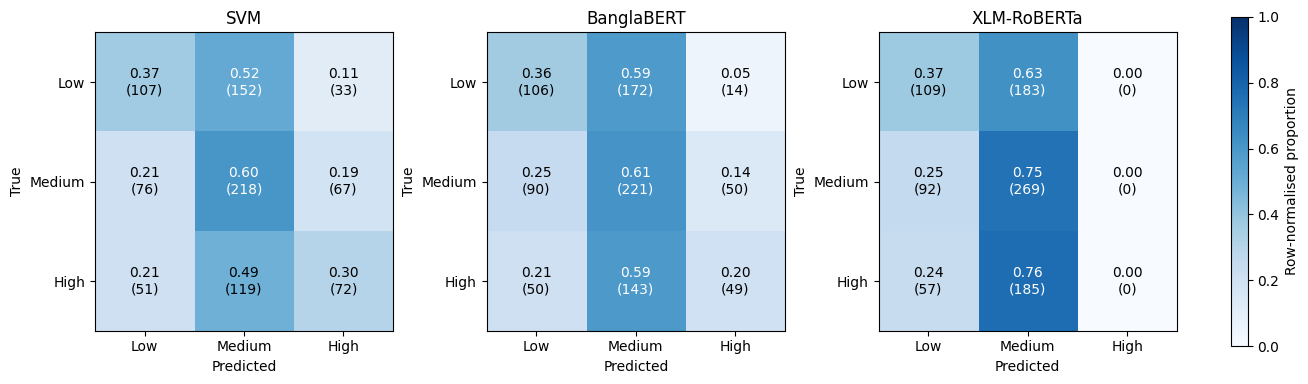

In [4]:
import matplotlib.pyplot as plt

labels = ["Low", "Medium", "High"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), constrained_layout=True)

for ax, (name, cm) in zip(axes, cms.items()):
    norm = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(name, fontsize=12)
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(labels); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for i in range(3):
        for j in range(3):
            c = "white" if norm[i, j] > 0.5 else "black"
            ax.text(j, i, f"{norm[i,j]:.2f}\n({cm[i,j]})",
                    ha="center", va="center", color=c, fontsize=10)

fig.colorbar(im, ax=axes, shrink=0.8, label="Row-normalised proportion")
plt.savefig("/kaggle/working/fig_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.savefig("/kaggle/working/fig_confusion_matrices.pdf", bbox_inches="tight")
plt.show()

In [5]:
from sklearn.metrics import cohen_kappa_score

def wilson(k, n, z=1.96):
    p = k/n; d = 1 + z*z/n; c = p + z*z/(2*n)
    m = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))
    return (c-m)/d*100, (c+m)/d*100

for name, cm in cms.items():
    yt = np.repeat([0,1,2], cm.sum(axis=1))
    yp = np.concatenate([np.repeat([0,1,2], cm[i]) for i in range(3)])
    qwk = cohen_kappa_score(yt, yp, weights="quadratic")
    mae = np.abs(yt - yp).mean()
    lo, hi = wilson(cm.trace(), 895)
    print(f"{name:12s} QWK={qwk:.3f}  MAE={mae:.3f}  Acc 95% CI=[{lo:.2f}, {hi:.2f}]")

SVM          QWK=0.196  MAE=0.650  Acc 95% CI=[41.13, 47.63]
BanglaBERT   QWK=0.190  MAE=0.651  Acc 95% CI=[38.82, 45.27]
XLM-RoBERTa  QWK=0.099  MAE=0.641  Acc 95% CI=[39.04, 45.50]


In [6]:
import os
from IPython.display import FileLink, display

print(os.listdir("/kaggle/working"))
os.chdir("/kaggle/working")
display(FileLink("fig_confusion_matrices.pdf"))
display(FileLink("fig_confusion_matrices.png"))

['.virtual_documents', 'fig_confusion_matrices.png', 'fig_confusion_matrices.pdf']


/kaggle/working/fig_confusion_matrices.pdf

/kaggle/working/fig_confusion_matrices.png